# 30-day hospital readmission after a diabetes encounter

Which discharge encounters had the highest observed 30-day readmission rates, and how much could a simple discharge-time model distinguish higher- and lower-risk encounters? The analysis uses the [UCI Diabetes 130-US Hospitals dataset](https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008). See the [README](../README.md) for setup and a results summary.

## Cohort and decision point

The unit of analysis is a hospital encounter for a patient with diabetes. The cohort excludes in-hospital deaths, discharge to hospice, and invalid gender records. The model uses information available by discharge, including prior utilization and documented inpatient treatment. The patient identifier is used only to keep repeat encounters together during evaluation.

# Load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 60)

# Resolve paths robustly whether the notebook is run from the repo root or notebooks/
candidate_roots = [
    os.getcwd(),
    os.path.abspath(os.path.join(os.getcwd(), "..")),
]

DATA_PATH = None
MAPPING_PATH = None

for root in candidate_roots:
    candidate_data = os.path.join(root, "data", "raw", "diabetic_data.csv")
    candidate_map = os.path.join(root, "data", "raw", "IDS_mapping.csv")
    if os.path.exists(candidate_data) and os.path.exists(candidate_map):
        DATA_PATH = candidate_data
        MAPPING_PATH = candidate_map
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find diabetic_data.csv and IDS_mapping.csv in data/raw/ "
        "from either the current directory or its parent."
    )

df = pd.read_csv(DATA_PATH)
ids_map = pd.read_csv(MAPPING_PATH)

print("df shape:", df.shape)
print("ids_map shape:", ids_map.shape)
print("Columns in diabetic_data.csv:")
print(df.columns.tolist())

display(df.drop(columns=["encounter_id", "patient_nbr"]).head())
display(ids_map.head())

df shape: (101766, 50)
ids_map shape: (67, 2)
Columns in diabetic_data.csv:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


,race,gender,age,weight,admission_type_id,discharge_disposition_id,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),?,6,25,...,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),?,1,1,...,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),?,1,1,...,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),?,1,1,...,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),?,1,1,...,No,No,No,Ch,Yes,NO


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available


# Data dictionary & target definition

In [2]:
fields = [
    "encounter_id",
    "patient_nbr",
    "race",
    "gender",
    "age",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "payer_code",
    "medical_specialty",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
    "readmitted",
    "readmit_30d",
]

field_usage = {
    "encounter_id": "record identifier",
    "patient_nbr": "patient identifier",
    "race": "demographic feature",
    "gender": "demographic feature",
    "age": "demographic feature",
    "admission_type_id": "encounter context feature",
    "discharge_disposition_id": "encounter outcome feature",
    "admission_source_id": "encounter context feature",
    "time_in_hospital": "utilization feature",
    "payer_code": "administrative feature",
    "medical_specialty": "provider context feature",
    "num_lab_procedures": "utilization feature",
    "num_procedures": "utilization feature",
    "num_medications": "treatment intensity feature",
    "number_outpatient": "prior utilization feature",
    "number_emergency": "prior utilization feature",
    "number_inpatient": "prior utilization feature",
    "diag_1": "clinical diagnosis feature",
    "diag_2": "clinical diagnosis feature",
    "diag_3": "clinical diagnosis feature",
    "max_glu_serum": "lab result feature",
    "A1Cresult": "lab result feature",
    "insulin": "medication feature",
    "change": "medication change feature",
    "diabetesMed": "medication indicator",
    "readmitted": "original outcome field",
    "readmit_30d": "binary modeling target",
}

field_notes = {
    "encounter_id": "unique encounter identifier",
    "patient_nbr": "patient-level identifier; can repeat across encounters",
    "race": "categorical patient race field",
    "gender": "categorical patient gender field",
    "age": "recorded as age bands",
    "admission_type_id": "coded field; refer to IDS mapping file",
    "discharge_disposition_id": "coded field; refer to IDS mapping file",
    "admission_source_id": "coded field; refer to IDS mapping file",
    "time_in_hospital": "length of stay in days",
    "payer_code": "often sparse in this dataset",
    "medical_specialty": "often sparse and high-cardinality",
    "num_lab_procedures": "count of lab procedures during encounter",
    "num_procedures": "count of procedures during encounter",
    "num_medications": "count of medications during encounter",
    "number_outpatient": "historical outpatient visits",
    "number_emergency": "historical emergency visits",
    "number_inpatient": "historical inpatient visits",
    "diag_1": "primary diagnosis code",
    "diag_2": "secondary diagnosis code",
    "diag_3": "tertiary diagnosis code",
    "max_glu_serum": "glucose serum test result category",
    "A1Cresult": "A1C test result category",
    "insulin": "insulin medication status",
    "change": "whether diabetes medications changed",
    "diabetesMed": "whether any diabetes medication was prescribed",
    "readmitted": "multiclass outcome in source data (<30, >30, NO)",
    "readmit_30d": "engineered target derived from readmitted",
}

data_dictionary = pd.DataFrame(
    {
        "field": fields,
        "used_for": [field_usage.get(field, "candidate feature") for field in fields],
        "notes": [field_notes.get(field, "") if field in df.columns else "not present" for field in fields],
    }
)

missing_values_summary = (
    pd.DataFrame(
        {
            "field": df.columns,
            "missing_count": df.isna().sum().values,
            "missing_pct": (df.isna().mean().values * 100).round(2),
        }
    )
    .sort_values(["missing_count", "field"], ascending=[False, True])
    .reset_index(drop=True)
)

display(data_dictionary)
display(missing_values_summary)


,field,used_for,notes
0,encounter_id,record identifier,unique encounter identifier
1,patient_nbr,patient identifier,patient-level identifier; can repeat across encounters
2,race,demographic feature,categorical patient race field
3,gender,demographic feature,categorical patient gender field
4,age,demographic feature,recorded as age bands
5,admission_type_id,encounter context feature,coded field; refer to IDS mapping file
6,discharge_disposition_id,encounter outcome feature,coded field; refer to IDS mapping file
7,admission_source_id,encounter context feature,coded field; refer to IDS mapping file
8,time_in_hospital,utilization feature,length of stay in days
9,payer_code,administrative feature,often sparse in this dataset


,field,missing_count,missing_pct
0,max_glu_serum,96420,94.75
1,A1Cresult,84748,83.28
2,acarbose,0,0.00
3,acetohexamide,0,0.00
4,admission_source_id,0,0.00
5,admission_type_id,0,0.00
6,age,0,0.00
7,change,0,0.00
8,chlorpropamide,0,0.00
9,citoglipton,0,0.00


**Target definition:** `readmit_30d = 1` when `readmitted == "<30"` and `0` otherwise.

# Cleaning & preprocessing

In [3]:
shape_before_cleaning = df.shape

# Disposition codes follow the accompanying UCI mapping.
excluded_dispositions = {11, 13, 14, 19, 20, 21}
df_clean = df.loc[~df["discharge_disposition_id"].isin(excluded_dispositions)].replace("?", np.nan).copy()

if "gender" in df_clean.columns:
    df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"].copy()

if "readmit_30d" not in df_clean.columns:
    if "readmitted" not in df_clean.columns:
        raise KeyError("Neither 'readmit_30d' nor 'readmitted' is available for target creation.")
    df_clean["readmit_30d"] = (df_clean["readmitted"] == "<30").astype(int)

if "age" not in df_clean.columns:
    raise KeyError("Column 'age' is missing from df_clean.")

df_clean["age_band_clean"] = (
    df_clean["age"]
    .astype(str)
    .str.strip()
    .str.replace("[", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("-", " to ", regex=False)
)

shape_after_cleaning = df_clean.shape

print("Shape before cleaning:", shape_before_cleaning)
print("Shape after cleaning:", shape_after_cleaning)
print("readmit_30d class balance:")
print(df_clean["readmit_30d"].value_counts(dropna=False))

modeling_key_fields = [
    "race",
    "gender",
    "age",
    "age_band_clean",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "payer_code",
    "medical_specialty",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
    "readmit_30d",
]

available_modeling_fields = [field for field in modeling_key_fields if field in df_clean.columns]
missing_key_fields_summary = (
    pd.DataFrame(
        {
            "field": available_modeling_fields,
            "missing_count": [int(df_clean[field].isna().sum()) for field in available_modeling_fields],
        }
    )
    .sort_values(["missing_count", "field"], ascending=[False, True])
    .reset_index(drop=True)
)

display(missing_key_fields_summary)

Shape before cleaning: (101766, 50)
Shape after cleaning: (99340, 52)
readmit_30d class balance:
readmit_30d
0    88026
1    11314
Name: count, dtype: int64


,field,missing_count
0,max_glu_serum,94188
1,A1Cresult,82506
2,medical_specialty,48614
3,payer_code,39397
4,race,2232
5,diag_3,1419
6,diag_2,356
7,diag_1,20
8,admission_source_id,0
9,admission_type_id,0


# Descriptive readmission analysis

Overall 30-day readmission rate: 11.39%


,age_band_clean,encounters,readmit_30d_rate
0,20 to 30,1649,0.143117
1,80 to 90,16434,0.125654
2,70 to 80,25329,0.120573
3,90 to 100,2589,0.118965
4,60 to 70,22058,0.113020
5,30 to 40,3764,0.112646
6,40 to 50,9607,0.106589
7,50 to 60,17060,0.097714
8,10 to 20,690,0.057971
9,0 to 10,160,0.018750


,gender,encounters,readmit_30d_rate
0,Female,53454,0.114641
1,Male,45886,0.113019


,race,encounters,readmit_30d_rate
0,Caucasian,74220,0.115279
1,AfricanAmerican,18772,0.114479
2,Hispanic,2017,0.105107
3,Asian,628,0.103503
4,Other,1471,0.097893
5,NaN,2232,0.084229


,admission_type_id,encounters,readmit_30d_rate
0,1,52369,0.118276
1,2,18132,0.113501
2,6,5207,0.111965
3,5,4617,0.106779
4,3,18667,0.104891
5,4,10,0.100000
6,8,320,0.084375
7,7,18,0.000000


,discharge_disposition_id,encounters,readmit_30d_rate
0,12,3,0.666667
1,15,63,0.444444
2,9,21,0.428571
3,28,139,0.366906
4,22,1992,0.277108
5,5,1184,0.208615
6,2,2128,0.160714
7,3,13954,0.146625
8,24,48,0.145833
9,7,623,0.144462


,time_in_hospital,encounters,readmit_30d_rate
0,10,2262,0.148099
1,8,4270,0.145902
2,9,2879,0.142758
3,12,1383,0.139552
4,14,995,0.134673
5,7,5696,0.131145
6,13,1152,0.129340
7,6,7355,0.128620
8,5,9749,0.122679
9,4,13684,0.119921


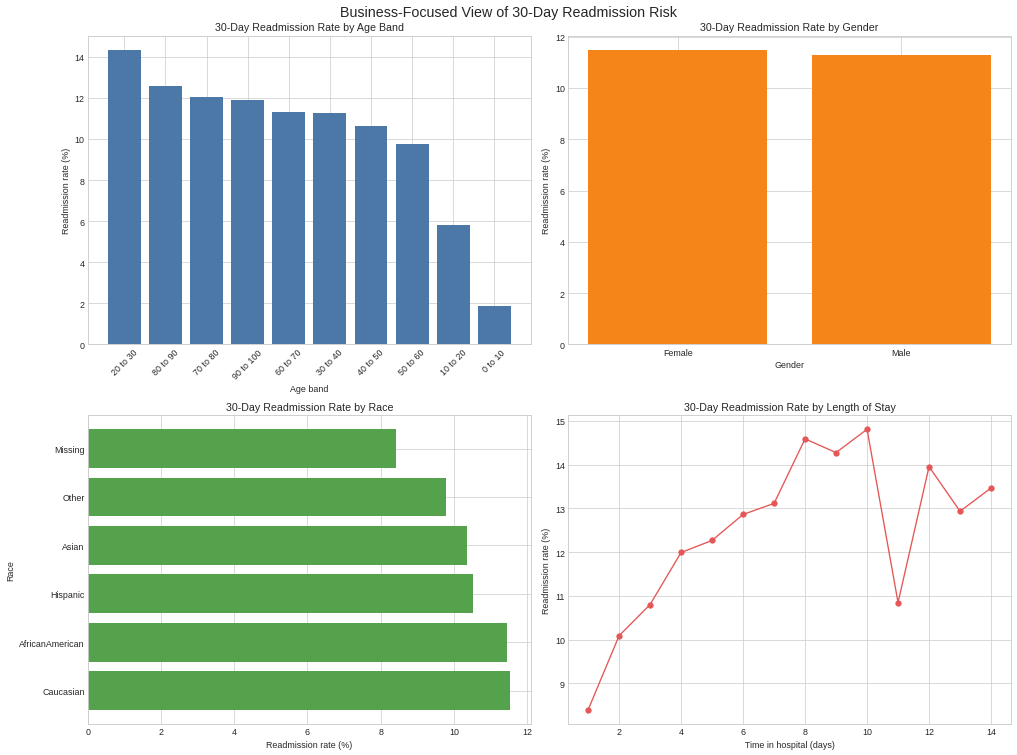

In [4]:
if "readmit_30d" not in df_clean.columns:
    raise KeyError("Column 'readmit_30d' is missing from df_clean.")

def readmission_rate_table(dataframe, group_col):
    if group_col not in dataframe.columns:
        return pd.DataFrame(columns=[group_col, "encounters", "readmit_30d_rate"])
    return (
        dataframe.groupby(group_col, dropna=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={"count": "encounters", "mean": "readmit_30d_rate"})
        .sort_values("readmit_30d_rate", ascending=False)
        .reset_index(drop=True)
    )

overall_readmission_rate = df_clean["readmit_30d"].mean()
age_readmission = readmission_rate_table(df_clean, "age_band_clean")
gender_readmission = readmission_rate_table(df_clean, "gender")
race_readmission = readmission_rate_table(df_clean, "race")
admission_type_readmission = readmission_rate_table(df_clean, "admission_type_id")
discharge_disposition_readmission = readmission_rate_table(df_clean, "discharge_disposition_id")
time_in_hospital_readmission = readmission_rate_table(df_clean, "time_in_hospital")

print(f"Overall 30-day readmission rate: {overall_readmission_rate:.2%}")

display(age_readmission)
display(gender_readmission)
display(race_readmission)
display(admission_type_readmission)
display(discharge_disposition_readmission)
display(time_in_hospital_readmission)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

age_plot = age_readmission.copy()
axes[0, 0].bar(age_plot["age_band_clean"].astype(str), age_plot["readmit_30d_rate"] * 100, color="#4C78A8")
axes[0, 0].set_title("30-Day Readmission Rate by Age Band")
axes[0, 0].set_xlabel("Age band")
axes[0, 0].set_ylabel("Readmission rate (%)")
axes[0, 0].tick_params(axis="x", rotation=45)

gender_plot = gender_readmission.copy()
axes[0, 1].bar(gender_plot["gender"].fillna("Missing").astype(str), gender_plot["readmit_30d_rate"] * 100, color="#F58518")
axes[0, 1].set_title("30-Day Readmission Rate by Gender")
axes[0, 1].set_xlabel("Gender")
axes[0, 1].set_ylabel("Readmission rate (%)")

race_plot = race_readmission.copy()
race_plot["race"] = race_plot["race"].fillna("Missing").astype(str)
axes[1, 0].barh(race_plot["race"], race_plot["readmit_30d_rate"] * 100, color="#54A24B")
axes[1, 0].set_title("30-Day Readmission Rate by Race")
axes[1, 0].set_xlabel("Readmission rate (%)")
axes[1, 0].set_ylabel("Race")

los_plot = time_in_hospital_readmission.sort_values("time_in_hospital")
axes[1, 1].plot(los_plot["time_in_hospital"], los_plot["readmit_30d_rate"] * 100, marker="o", color="#E45756")
axes[1, 1].set_title("30-Day Readmission Rate by Length of Stay")
axes[1, 1].set_xlabel("Time in hospital (days)")
axes[1, 1].set_ylabel("Readmission rate (%)")

plt.suptitle("Business-Focused View of 30-Day Readmission Risk", fontsize=16)
plt.tight_layout()
plt.show()


# Utilization & operational drivers


Readmission pattern for number_outpatient:

Readmission pattern for number_emergency:

Readmission pattern for number_inpatient:

Readmission pattern for num_lab_procedures:

Readmission pattern for num_procedures:

Readmission pattern for num_medications:

Readmission pattern for diabetesMed:

Readmission pattern for insulin:

Readmission pattern for A1Cresult:

Readmission pattern for change:


,category,encounters,readmit_30d_rate
0,40,1,1.000000
1,23,2,0.500000
2,19,3,0.333333
3,13,30,0.200000
4,22,5,0.200000
5,14,28,0.178571
6,12,29,0.172414
7,9,82,0.158537
8,7,154,0.155844
9,4,1077,0.154132


,category,encounters,readmit_30d_rate
0,28,1,1.000000
1,64,1,1.000000
2,22,6,0.500000
3,19,4,0.500000
4,20,4,0.500000
5,21,2,0.500000
6,16,5,0.400000
7,9,33,0.363636
8,10,34,0.352941
9,13,12,0.333333


,category,encounters,readmit_30d_rate
0,15,9,1.000000
1,17,1,1.000000
2,21,1,1.000000
3,11,49,0.673469
4,13,18,0.555556
5,12,32,0.531250
6,19,2,0.500000
7,8,145,0.462069
8,10,59,0.440678
9,9,109,0.431193


,category,encounters,readmit_30d_rate
0,0-20,14304,0.099762
1,21-40,27307,0.107994
2,41-60,39121,0.118427
3,61-80,16825,0.123269
4,81+,1783,0.129557


,category,encounters,readmit_30d_rate
0,0,45679,0.112568
1,1,20249,0.124599
2,2-3,21575,0.112399
3,4+,11837,0.103405


,category,encounters,readmit_30d_rate
0,0-10,25311,0.092134
1,11-20,50942,0.116564
2,21-30,18076,0.132441
3,31-40,3698,0.134397
4,41+,1313,0.116527


,category,encounters,readmit_30d_rate
0,Yes,76717,0.118370
1,No,22623,0.098705


,category,encounters,readmit_30d_rate
0,Down,11908,0.142173
1,Up,10987,0.133339
2,Steady,30069,0.113738
3,No,46376,0.102122


,category,encounters,readmit_30d_rate
0,Missing,82506,0.116852
1,>7,3775,0.101457
2,>8,8137,0.099422
3,Norm,4922,0.097725


,category,encounters,readmit_30d_rate
0,Ch,46120,0.120230
1,No,53220,0.108399


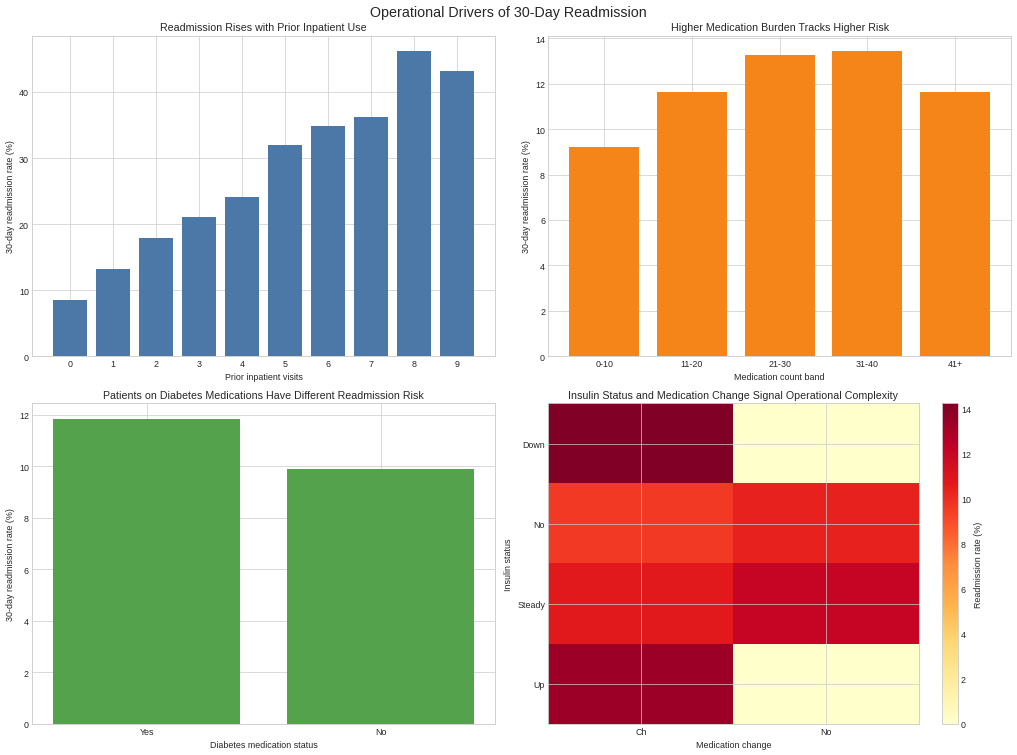

In [5]:
if "readmit_30d" not in df_clean.columns:
    raise KeyError("Column 'readmit_30d' is missing from df_clean.")

driver_fields = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "diabetesMed",
    "insulin",
    "A1Cresult",
    "change",
]

for field in driver_fields:
    if field not in df_clean.columns:
        raise KeyError(f"Column '{field}' is missing from df_clean.")

def summarize_driver(dataframe, group_col):
    summary = (
        dataframe.groupby(group_col, dropna=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={group_col: "category", "count": "encounters", "mean": "readmit_30d_rate"})
    )
    summary["category"] = summary["category"].fillna("Missing").astype(str)
    return summary.sort_values(["readmit_30d_rate", "encounters"], ascending=[False, False]).reset_index(drop=True)

def summarize_binned_driver(dataframe, source_col, bins, labels, ordered=True):
    binned = pd.cut(dataframe[source_col], bins=bins, labels=labels, include_lowest=True, right=True, ordered=ordered)
    summary = (
        dataframe.assign(driver_band=binned)
        .groupby("driver_band", dropna=False, observed=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={"driver_band": "category", "count": "encounters", "mean": "readmit_30d_rate"})
    )
    summary["category"] = summary["category"].astype(str)
    return summary

outpatient_summary = summarize_driver(df_clean, "number_outpatient")
emergency_summary = summarize_driver(df_clean, "number_emergency")
inpatient_summary = summarize_driver(df_clean, "number_inpatient")
diabetes_med_summary = summarize_driver(df_clean, "diabetesMed")
insulin_summary = summarize_driver(df_clean, "insulin")
a1c_summary = summarize_driver(df_clean, "A1Cresult")
change_summary = summarize_driver(df_clean, "change")

lab_bins = [-np.inf, 20, 40, 60, 80, np.inf]
lab_labels = ["0-20", "21-40", "41-60", "61-80", "81+"]
lab_summary = summarize_binned_driver(df_clean, "num_lab_procedures", lab_bins, lab_labels)

procedure_bins = [-np.inf, 0, 1, 3, np.inf]
procedure_labels = ["0", "1", "2-3", "4+"]
procedure_summary = summarize_binned_driver(df_clean, "num_procedures", procedure_bins, procedure_labels)

medication_bins = [-np.inf, 10, 20, 30, 40, np.inf]
medication_labels = ["0-10", "11-20", "21-30", "31-40", "41+"]
medication_summary = summarize_binned_driver(df_clean, "num_medications", medication_bins, medication_labels)

operational_driver_tables = {
    "number_outpatient": outpatient_summary,
    "number_emergency": emergency_summary,
    "number_inpatient": inpatient_summary,
    "num_lab_procedures": lab_summary,
    "num_procedures": procedure_summary,
    "num_medications": medication_summary,
    "diabetesMed": diabetes_med_summary,
    "insulin": insulin_summary,
    "A1Cresult": a1c_summary,
    "change": change_summary,
}

for field_name, summary_table in operational_driver_tables.items():
    print(f"\nReadmission pattern for {field_name}:")
    display(summary_table)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

prior_use_plot = (
    df_clean.groupby(["number_inpatient", "number_emergency", "number_outpatient"], dropna=False)["readmit_30d"]
    .mean()
)

inpatient_plot = inpatient_summary.sort_values("category", key=lambda s: pd.to_numeric(s, errors="coerce")).head(10)
axes[0, 0].bar(inpatient_plot["category"], inpatient_plot["readmit_30d_rate"] * 100, color="#4C78A8")
axes[0, 0].set_title("Readmission Rises with Prior Inpatient Use")
axes[0, 0].set_xlabel("Prior inpatient visits")
axes[0, 0].set_ylabel("30-day readmission rate (%)")

med_plot = medication_summary.copy()
axes[0, 1].bar(med_plot["category"], med_plot["readmit_30d_rate"] * 100, color="#F58518")
axes[0, 1].set_title("Higher Medication Burden Tracks Higher Risk")
axes[0, 1].set_xlabel("Medication count band")
axes[0, 1].set_ylabel("30-day readmission rate (%)")

diabetes_med_plot = diabetes_med_summary.copy()
axes[1, 0].bar(diabetes_med_plot["category"], diabetes_med_plot["readmit_30d_rate"] * 100, color="#54A24B")
axes[1, 0].set_title("Patients on Diabetes Medications Have Different Readmission Risk")
axes[1, 0].set_xlabel("Diabetes medication status")
axes[1, 0].set_ylabel("30-day readmission rate (%)")

insulin_change_plot = (
    df_clean.groupby(["insulin", "change"], dropna=False)["readmit_30d"]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={"count": "encounters", "mean": "readmit_30d_rate"})
)
pivot_plot = insulin_change_plot.pivot(index="insulin", columns="change", values="readmit_30d_rate").fillna(0)
pivot_plot = pivot_plot.reindex(sorted(pivot_plot.index.astype(str)), axis=0)
pivot_plot = pivot_plot.reindex(sorted(pivot_plot.columns.astype(str)), axis=1)
im = axes[1, 1].imshow(pivot_plot.values * 100, cmap="YlOrRd", aspect="auto")
axes[1, 1].set_title("Insulin Status and Medication Change Signal Operational Complexity")
axes[1, 1].set_xlabel("Medication change")
axes[1, 1].set_ylabel("Insulin status")
axes[1, 1].set_xticks(range(len(pivot_plot.columns)))
axes[1, 1].set_xticklabels(pivot_plot.columns)
axes[1, 1].set_yticks(range(len(pivot_plot.index)))
axes[1, 1].set_yticklabels(pivot_plot.index)
fig.colorbar(im, ax=axes[1, 1], label="Readmission rate (%)")

plt.suptitle("Operational Drivers of 30-Day Readmission", fontsize=16)
plt.tight_layout()
plt.show()


## Patient-disjoint model evaluation

Compare a class-weighted logistic regression with a constant prevalence baseline using a held-out group of patients. Average precision is the primary ranking metric for this imbalanced outcome. Precision and recall describe the tradeoff at the model's default decision threshold.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "age", "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "A1Cresult", "insulin", "change", "diabetesMed",
]
numeric_features = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient",
]
X = df_clean[categorical_features + numeric_features].copy()
X[categorical_features] = X[categorical_features].astype("object")
y = df_clean["readmit_30d"]
groups = df_clean["patient_nbr"]

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups))
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

preprocessor = ColumnTransformer([
    ("categorical", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(handle_unknown="ignore", drop="first")), categorical_features),
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_features),
])
model = make_pipeline(preprocessor, LogisticRegression(max_iter=1000, class_weight="balanced"))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

metrics = {
    "average_precision": average_precision_score(y_test, y_score),
    "prevalence_baseline_ap": y_test.mean(),
    "roc_auc": roc_auc_score(y_test, y_score),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
}
print(f"Training encounters: {len(X_train):,} | Test encounters: {len(X_test):,}")
display(pd.Series(metrics, name="value").to_frame())

Training encounters: 79,567 | Test encounters: 19,773


,value
average_precision,0.224366
prevalence_baseline_ap,0.113488
roc_auc,0.665528
precision,0.187864
recall,0.531194
f1,0.277564


# Feature interpretation

,log-odds coefficient
discharge_disposition_id = 23 (vs 1),-0.587719
admission_source_id = 5 (vs 1),-0.281073
insulin = No (vs Down),-0.277539
insulin = Steady (vs Down),-0.210186
admission_source_id = 6 (vs 1),-0.164299
admission_source_id = 4 (vs 1),-0.138542
age = [20-30) (vs [0-10)),0.969502
age = [60-70) (vs [0-10)),0.993960
age = [80-90) (vs [0-10)),1.047839
age = [70-80) (vs [0-10)),1.055551


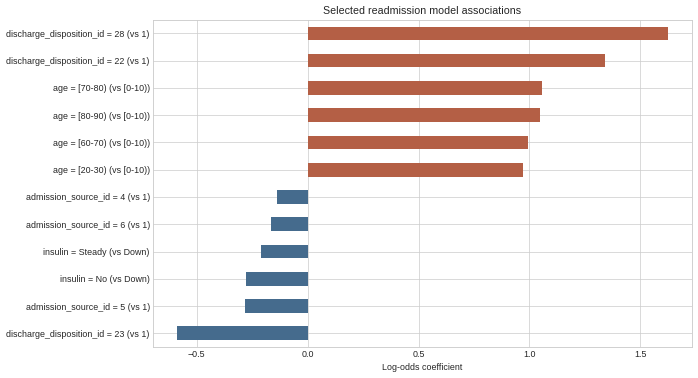

In [7]:
preprocessor = model.named_steps["columntransformer"]
classifier = model.named_steps["logisticregression"]
encoder = preprocessor.named_transformers_["categorical"].named_steps["onehotencoder"]

labels = [
    f"{field} = {category} (vs {categories[reference]})"
    for field, categories, reference in zip(categorical_features, encoder.categories_, encoder.drop_idx_)
    for idx, category in enumerate(categories) if idx != reference
]
labels.extend(f"{field} (+1 SD)" for field in numeric_features)
coefficients = pd.Series(classifier.coef_.ravel(), index=labels, name="log-odds coefficient")
common_categories = {
    f"{field} = {category} (vs {categories[reference]})"
    for field, categories, reference in zip(categorical_features, encoder.categories_, encoder.drop_idx_)
    for idx, category in enumerate(categories)
    if idx != reference and X_train[field].eq(category).sum() >= 100 and X_train[field].eq(categories[reference]).sum() >= 100
}
coefficients = coefficients.loc[coefficients.index.isin(common_categories | set(labels[-len(numeric_features):]))]
extremes = pd.concat([coefficients.nsmallest(6), coefficients.nlargest(6)]).sort_values()
display(extremes.to_frame())
ax = extremes.plot.barh(figsize=(11, 6), color=["#456B8D" if value < 0 else "#B45F45" for value in extremes])
ax.set_xlabel("Log-odds coefficient")
ax.set_title("Selected readmission model associations")
plt.tight_layout()
plt.show()

The chart shows selected coefficients for one-standard-deviation changes in numeric features and comparisons with the stated reference category. Rare categorical comparisons are suppressed. Coefficients are conditional associations in this fitted model.

# Executive summary & recommendations

In [8]:
from IPython.display import Markdown, display

no_prior = inpatient_summary.loc[inpatient_summary["category"].astype(str).eq("0")].iloc[0]
three_prior = inpatient_summary.loc[inpatient_summary["category"].astype(str).eq("3")].iloc[0]
display(Markdown(f"""
- **Cohort.** {len(df_clean):,} eligible encounters, with an observed 30-day readmission rate of {overall_readmission_rate:.1%}.
- **Prior utilization.** The rate was {no_prior['readmit_30d_rate']:.1%} for encounters with no prior inpatient visits (n={no_prior['encounters']:,}) and {three_prior['readmit_30d_rate']:.1%} for those with three (n={three_prior['encounters']:,}).
- **Model.** Patient-disjoint test average precision was {metrics['average_precision']:.3f}, versus a prevalence benchmark of {metrics['prevalence_baseline_ap']:.3f}. ROC-AUC was {metrics['roc_auc']:.3f}. At the default threshold, precision was {metrics['precision']:.1%} and recall was {metrics['recall']:.1%}.
- **Operational interpretation.** Prior inpatient utilization is a reasonable segment for further review. Evaluating any outreach policy would require current local data, capacity-based thresholds, calibration, and subgroup checks.
"""))


- **Cohort.** 99,340 eligible encounters, with an observed 30-day readmission rate of 11.4%.
- **Prior utilization.** The rate was 8.6% for encounters with no prior inpatient visits (n=66,242) and 21.0% for those with three (n=3,271).
- **Model.** Patient-disjoint test average precision was 0.224, versus a prevalence benchmark of 0.113. ROC-AUC was 0.666. At the default threshold, precision was 18.8% and recall was 53.1%.
- **Operational interpretation.** Prior inpatient utilization is a reasonable segment for further review. Evaluating any outreach policy would require current local data, capacity-based thresholds, calibration, and subgroup checks.


# Limitations

The 1999–2008 cohort is historical. Encounters from the same patient are kept together in evaluation, but the study has no temporal or external site validation. The data do not establish which readmissions were avoidable. Repeat encounters contribute separately to descriptive rates, and small segments can have unstable estimates. Class weighting changes the interpretation of raw scores, and the model has no calibration or subgroup performance validation.